In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from datasets import load_dataset

In [3]:
data=load_dataset('dair-ai/emotion')


In [4]:
data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [5]:
train=data['train']['text']
train_label=data['train']['label']

test=data['test']['text']
test_label=data['test']['label']

In [6]:
label_names=data['train']['label'].features.names

In [61]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [7]:
train=pd.DataFrame({
    'text': train ,
    'labels':[label_names[i] for i in train_label]
})
test=pd.DataFrame({
    'text':test ,
    'labels':[label_names[i] for i in test_label]
})

<Axes: xlabel='labels', ylabel='count'>

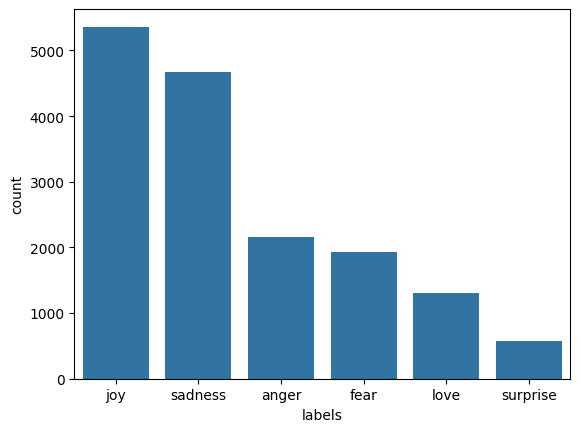

In [8]:
sns.barplot(train['labels'].value_counts())

In [9]:
# Preprocessing Of NLP

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


In [11]:
max_tok=10000
tokenizer=Tokenizer(num_words=max_tok,oov_token='')
tokenizer.fit_on_texts(train['text'])

In [12]:
train_seq=tokenizer.texts_to_sequences(train['text'])
test_seq=tokenizer.texts_to_sequences(test['text'])

pad_train=pad_sequences(train_seq,maxlen=50,padding='post',truncating='post')
pad_test=pad_sequences(test_seq,maxlen=50,padding='post',truncating='post')
trian_label=np.array(train_label)
test_label=np.array(test_label)
num_columns=len(np.unique(train.labels))

SyntaxError: closing parenthesis ']' does not match opening parenthesis '{' (2476642963.py, line 1)

In [14]:
from sklearn.utils import class_weight
class_imb=class_weight.compute_class_weight( 
    class_weight = 'balanced',
    classes = np.unique(train.labels),
    y = train.labels 
)

class_weight= dict(enumerate(class_imb))

# Here we define where our model is stop for prevent of overfitting

from tensorflow.keras.callbacks import EarlyStopping
stopping=EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True)
                        

    

In [15]:
# NOW HERE WE USE THE MODELS LIKE RNN,LSTM AND GRU

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import RNN,LSTM,GRU,Embedding,Dropout,SimpleRNN,Dense,Bidirectional

In [17]:
rnn_model=Sequential([
    Embedding(input_dim=max_tok,output_dim=128,input_length=50),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_columns,activation='softmax')
])
    

In [18]:
rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [19]:
pad_train

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]],
      shape=(16000, 50), dtype=int32)

In [25]:
import tensorflow as tf
pad_train = tf.convert_to_tensor(np.array(pad_train), dtype=tf.int32)
train_label = tf.convert_to_tensor(train_label, dtype=tf.int32)
pad_test = tf.convert_to_tensor(np.array(pad_test), dtype=tf.int32)
test_label = tf.convert_to_tensor(test_label, dtype=tf.int32)


rnn_model.fit(
    pad_train,
    train_label,
    validation_data=(pad_test,test_label),
    batch_size=32,
    class_weight=class_weight,
    epochs=20,
    callbacks=[stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.2885 - loss: 2.2875 - val_accuracy: 0.3480 - val_loss: 1.7240
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.3244 - loss: 2.1515 - val_accuracy: 0.3460 - val_loss: 1.6603
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.3388 - loss: 2.1184 - val_accuracy: 0.3155 - val_loss: 1.6857
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.3449 - loss: 2.0869 - val_accuracy: 0.3425 - val_loss: 1.7038
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.3661 - loss: 2.0484 - val_accuracy: 0.2925 - val_loss: 1.7150


In [28]:
rnn_loss,rnn_accu=rnn_model.evaluate(pad_test,test_label)

print("RNN Model Loss IS :",rnn_loss)
print("RNN Model Accuracy Is : " ,rnn_accu)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3460 - loss: 1.6603
RNN Model Loss IS : 1.6603443622589111
RNN Model Accuracy Is :  0.34599998593330383


In [29]:
# LSTM MOdel USE 

In [38]:
lstm_model=Sequential([
    Embedding(input_dim=max_tok,output_dim=128,input_length=50),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dense(units=32,activation='softmax')
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [40]:
lstm_model.fit(
    pad_train,
    train_label,
    validation_data=(pad_test,test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[stopping]
)
lstm_loss,lstm_accu=lstm_model.evaluate(pad_test,test_label)
print('lstm_loss :',lstm_loss)
print('lstm accu :',lstm_accu)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.3350 - loss: 2.1355 - val_accuracy: 0.3475 - val_loss: 1.6869
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.3335 - loss: 2.1367 - val_accuracy: 0.3475 - val_loss: 1.6431
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.3330 - loss: 2.1360 - val_accuracy: 0.3475 - val_loss: 1.6723
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.3349 - loss: 2.1361 - val_accuracy: 0.3475 - val_loss: 1.6753
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.3338 - loss: 2.1372 - val_accuracy: 0.3475 - val_loss: 1.7110
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3475 - loss: 1.6431
lstm_loss : 1.6431496143341064
lstm accu : 0.3474999964237213


In [42]:
gru_model=Sequential([
    Embedding(input_dim=max_tok,output_dim=128,input_length=50),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dense(units=64,activation='softmax')
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    pad_train,
    train_label,
    validation_data=(pad_test,test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[stopping])

gru_loss,gru_acc=gru_model.evaluate(pad_test,test_label)


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.4204 - loss: 2.0276 - val_accuracy: 0.6980 - val_loss: 0.8996
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.8075 - loss: 0.5682 - val_accuracy: 0.8805 - val_loss: 0.4102
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.9060 - loss: 0.2592 - val_accuracy: 0.9180 - val_loss: 0.2515
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.9312 - loss: 0.1699 - val_accuracy: 0.9200 - val_loss: 0.2596
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.9426 - loss: 0.1409 - val_accuracy: 0.9235 - val_loss: 0.2576
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.9471 - loss: 0.1188 - val_accuracy: 0.9280 - val_loss: 0.2114
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.9528 - loss: 0.0991 - val_accuracy: 0.9275 - val_loss: 0.2132
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.9613 - loss: 0.0830 - 

NameError: name 'gru_accu' is not defined

In [44]:
print("gru loss:",gru_loss)
print("gru accuracy :",gru_acc)

gru loss: 0.21136584877967834
gru accuracy : 0.9279999732971191


In [45]:
# Bidirectional GRU 

In [47]:
bigru_model=Sequential([
    Embedding(input_dim=max_tok,output_dim=128,input_length=50),
    Bidirectional(GRU(units=128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dense(units=64,activation='softmax')
])

bigru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

bigru_model.fit(
    pad_train,
    train_label,
    validation_data=(pad_test,test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[stopping])

bigru_loss,bigru_acc=gru_model.evaluate(pad_test,test_label)
print("gru loss:",bigru_loss)
print("gru accuracy :",bigru_acc)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.5631 - loss: 1.5231 - val_accuracy: 0.8620 - val_loss: 0.4106
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9029 - loss: 0.2745 - val_accuracy: 0.9150 - val_loss: 0.2606
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9342 - loss: 0.1632 - val_accuracy: 0.9240 - val_loss: 0.2251
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9502 - loss: 0.1167 - val_accuracy: 0.9320 - val_loss: 0.1934
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9619 - loss: 0.0899 - val_accuracy: 0.9270 - val_loss: 0.2219
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9688 - loss: 0.0743 - val_accuracy: 0.9340 - val_loss: 0.2514
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.9735 - loss: 0.0606 - val_accuracy: 0.9270 - val_loss: 0.2531
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9280 - loss: 0.2114
gru loss: 0.2113

In [49]:
from sklearn.metrics import confusion_matrix

prediction =np.argmax(bigru_model.predict(pad_test),axis=1)


63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step


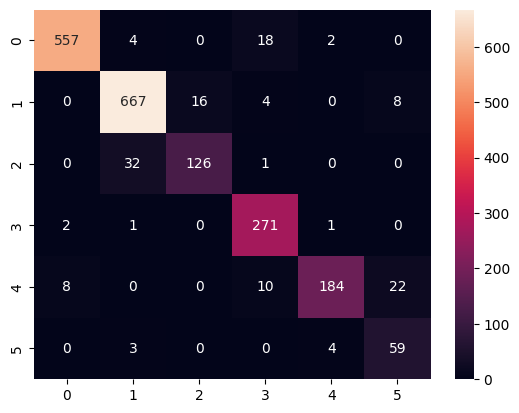

In [50]:
sns.heatmap(confusion_matrix(test_label,prediction),annot=True,fmt='d')
plt.show()

In [52]:

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(bigru_model.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [53]:
# SAVE THE MODEL 

In [58]:
import os 
import pickle
model_dir='Articale'
os.makedirs(model_dir,exist_ok=True)

bigru_model.save(os.path.join(model_dir,"bigru_model.keras"))

with open(os.path.join(model_dir,"tokenizer.pkl"),'wb') as file:
    pickle.dump(tokenizer,file)
